# d1 · Compression: teacher, size accounting and decision rules

**Task.** Make the c9 model as small as possible while keeping as much of its accuracy as we can, and show the
trade-off between size and accuracy at every step:

| notebook | question |
|---|---|
| d1 | what is being compressed, how size is measured, how decisions are made (this notebook, fixed before any result) |
| d2 | student architecture: how small can a model trained on the data alone get? |
| d3 | distillation: does learning from the teacher beat learning from the labels alone, at each size? |
| d4 | pruning: unstructured (zero out weights) vs structured (remove channels) |
| d5 | quantization: 8, 4 and 2 bits, post-training vs quantization-aware; real int8 in PyTorch |
| d6 | everything combined: the full size-accuracy frontier and the two final models |

**Teacher.** The r2 final model from c9 (seed 1738): plain 5-layer CNN, 5x5 kernels, widths 16-32-64-128,
276,628 parameters, val balanced accuracy 0.968. It is used unchanged: distillation targets come from it, and every
size is compared with it.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
sys.path.insert(0, ".")
from torch import nn
from lib import compress as C, dreport as R
from lib.train import DEVICE, prepare_data, predict
from lib.evaluation import evaluate
from lib.data import ARTIFACTS, CLASSES
tcfg = R.teacher_cfg()
teacher = C.load_teacher(DEVICE)
train, val = prepare_data(tcfg)
v = evaluate(val.y.cpu().numpy(), predict(teacher, val))
x1 = next(iter(val.batches(1)))[0]
size = C.size_report(teacher)
T0 = pd.Series({"parameters": sum(p.numel() for p in teacher.parameters()),
                "stored size (bytes, fp32, BN folded)": size["bytes"],
                "torch.save(state_dict) (bytes)": C.serialized_bytes(teacher),
                "CPU latency, 1 image, 1 thread (ms)": round(C.cpu_latency_ms(teacher, x1), 3),
                "val balanced accuracy": round(v["bal_acc"], 4), "tumour AUC": round(v["tumor_auc"], 4),
                **{f"recall {c}": round(v["recall"][c], 3) for c in CLASSES}})
T0

parameters                              2.766280e+05
stored size (bytes, fp32, BN folded)    1.105488e+06
torch.save(state_dict) (bytes)          1.119606e+06
CPU latency, 1 image, 1 thread (ms)     2.711000e+00
val balanced accuracy                   9.678000e-01
tumour AUC                              9.981000e-01
recall glioma                           9.710000e-01
recall meningioma                       9.310000e-01
recall no_tumor                         9.790000e-01
recall pituitary                        9.900000e-01
dtype: float64

## 1. How size is measured

**Size = bytes of the stored model as deployed** (`lib.compress.size_report`), the same function for every model:

* **BatchNorm is folded** into the preceding conv. At inference it is a fixed per-channel scale and shift, so it
  costs nothing extra once folded (it does cost bytes in a raw `state_dict`).
* **Weights** are stored at *b* bits (32 = fp32). Below 32 bits each output channel also stores one fp32 scale
  (per-channel symmetric quantization). **Biases stay fp32** (they are few).
* **Pruned weights**: stored dense, or sparse as a 1-bit mask over all positions plus the nonzero values, whichever
  is smaller. (A mask is cheaper than storing indices once more than about 1 in 32 weights survives.)

Parameter count and CPU latency are reported next to it. Latency is measured, not modelled, on this machine's CPU
(1 thread, 1 image); it depends on the hardware, so it is not the axis decisions are made on.

Check of the accounting against a real file: folded fp32 size vs `torch.save(state_dict)` above (the difference
is the unfolded BatchNorm parameters and the pickle overhead).

## 2. Where the teacher's bytes are

,layer,type,shape,weights,share
0,features.0.0,Conv2d,"(16, 1, 5, 5)",400,0.001
1,features.2.body.0,Conv2d,"(16, 16, 5, 5)",6400,0.023
2,features.4.body.0,Conv2d,"(32, 16, 5, 5)",12800,0.046
3,features.6.body.0,Conv2d,"(64, 32, 5, 5)",51200,0.185
4,features.8.body.0,Conv2d,"(128, 64, 5, 5)",204800,0.742
5,head.3,Linear,"(4, 128)",512,0.002


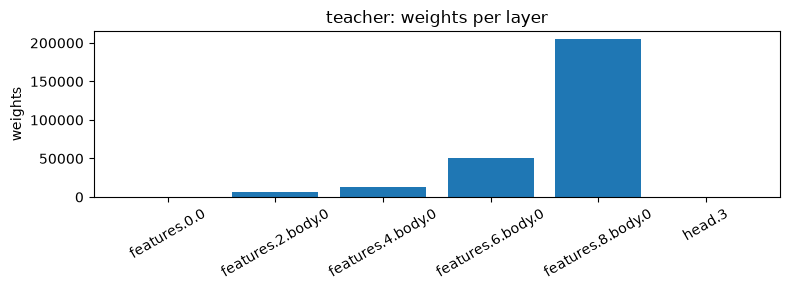

In [2]:
rows = []
for n, m in teacher.named_modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        rows.append({"layer": n, "type": type(m).__name__, "shape": tuple(m.weight.shape), "weights": m.weight.numel()})
L = pd.DataFrame(rows); L["share"] = (L.weights / L.weights.sum()).round(3)
display(L)
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(L.layer, L.weights); ax.set(ylabel="weights", title="teacher: weights per layer")
ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()

A 5x5 conv from *c_in* to *c_out* channels has 25·*c_in*·*c_out* weights, so the cost grows with the **square
of the width** and is dominated by the last stages. That points at the three levers d2 tests: **narrower**
layers (width), **smaller kernels** (3x3 = 9/25 of the weights) and **depthwise-separable** convolutions
(25·*c_in* + *c_in*·*c_out* instead of 25·*c_in*·*c_out*).

## 3. Decision rules (fixed here, before any compression result)

* **Two final models**, picked by one rule each from the d6 frontier:
  * **high-performance**: the smallest model whose mean val balanced accuracy is **at least 0.95**
    (teacher 0.968);
  * **tiny**: the smallest model whose mean val balanced accuracy is **at least 0.85** (just above the
    0.847 that the dataset authors report for their from-scratch CNN).
* **Every configuration is trained with 3 seeds** (1738-1740); "accuracy" means the mean val balanced accuracy of
  the 3 seeds, and the seed spread is shown as error bars. Pruning and quantization start from the same seed of
  the model they compress, so every compressed point also has 3 seeds.
* **Within a step** (for example: which temperature, which pruning method at a given size), the option with the
  highest mean wins, as in the c-notebooks.
* **Across sizes** nothing is "chosen": every point goes on the size-accuracy plot, and the **Pareto frontier**
  (models not beaten by a smaller and more accurate one) is what the next step builds on.
* **Training recipe for students** = the teacher's recipe from c5-c8 (grayscale, crop, 128 px, per-image
  normalisation, mild augmentation, Adam lr 0.03, batch 64, label smoothing, early stopping on val balanced
  accuracy with patience 20, 60 epochs). Only the architecture changes, unless a step says otherwise.
* **Val only.** The test set stays untouched, as in c10.

**Quantization tooling.** Simulated quantization (any bit width) is implemented in `lib.compress`: weights are
rounded per output channel to 2^(b-1)-1 levels each side of zero, and quantization-aware training uses a
straight-through estimator. Real int8 uses PyTorch FX graph mode quantization (`torch.ao.quantization.quantize_fx`,
backend `x86`), which PyTorch 2.6 keeps in maintenance mode next to the newer, still-prototype PT2E flow. The
simulated 8-bit and real int8 results are compared in d5 to check that the simulation is faithful.

In [3]:
rules = {"teacher": {"exp": "c9", "name": "final_s1738", "bal_acc": round(v["bal_acc"], 4), "bytes": size["bytes"]},
         "floors": R.FLOORS, "seeds": R.SEEDS3, "size": "lib.compress.size_report (BN folded, b-bit weights + fp32 "
         "per-channel scales and biases, sparse = 1-bit mask + nonzeros if smaller)"}
_ = (ARTIFACTS / "compress_rules.json").write_text(json.dumps(rules, indent=1))
rules

{'teacher': {'exp': 'c9',
  'name': 'final_s1738',
  'bal_acc': 0.9678,
  'bytes': 1105488},
 'floors': {'high-performance': 0.95, 'tiny': 0.85},
 'seeds': [1738, 1739, 1740],
 'size': 'lib.compress.size_report (BN folded, b-bit weights + fp32 per-channel scales and biases, sparse = 1-bit mask + nonzeros if smaller)'}